### Import data and inspect

here we import liberies and load data, then test our data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#here we have imported all the liberies that we need for this project

In [3]:
df=pd.read_csv("Flight Data.csv") #import the data

Below we are are going to inspect our data (just basics)

In [4]:
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [5]:
df.shape #no of colums and rows

(300153, 12)

In [6]:
df.info() #an total summery of the data

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  str    
 2   flight            300153 non-null  str    
 3   source_city       300153 non-null  str    
 4   departure_time    300153 non-null  str    
 5   stops             300153 non-null  str    
 6   arrival_time      300153 non-null  str    
 7   destination_city  300153 non-null  str    
 8   class             300153 non-null  str    
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 27.5 MB


In [7]:
df.isnull().sum() #check for null values in columns

Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

### Uderstand And Clean The Data

before training the model we have to understand and clean the data of anything that might create noise during training  of model

In [8]:
df.columns #column names

Index(['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time',
       'stops', 'arrival_time', 'destination_city', 'class', 'duration',
       'days_left', 'price'],
      dtype='str')

In [9]:
df.dtypes #checking data type of each column

Unnamed: 0            int64
airline                 str
flight                  str
source_city             str
departure_time          str
stops                   str
arrival_time            str
destination_city        str
class                   str
duration            float64
days_left             int64
price                 int64
dtype: object

In [10]:
df.duplicated().sum() #check for any duplicate rows

np.int64(0)

In [11]:
df.describe() #numerical value statistic 

,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [12]:
df.drop('Unnamed: 0',axis=1,inplace=True) #drop unwanted column 

In [13]:
df.head() #check the data to make sure its removed

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


### Exploratory Data Analysis (EDA)

Here we use different graphs and visualization to undertsand our data better more specifically how each factor affect the price.

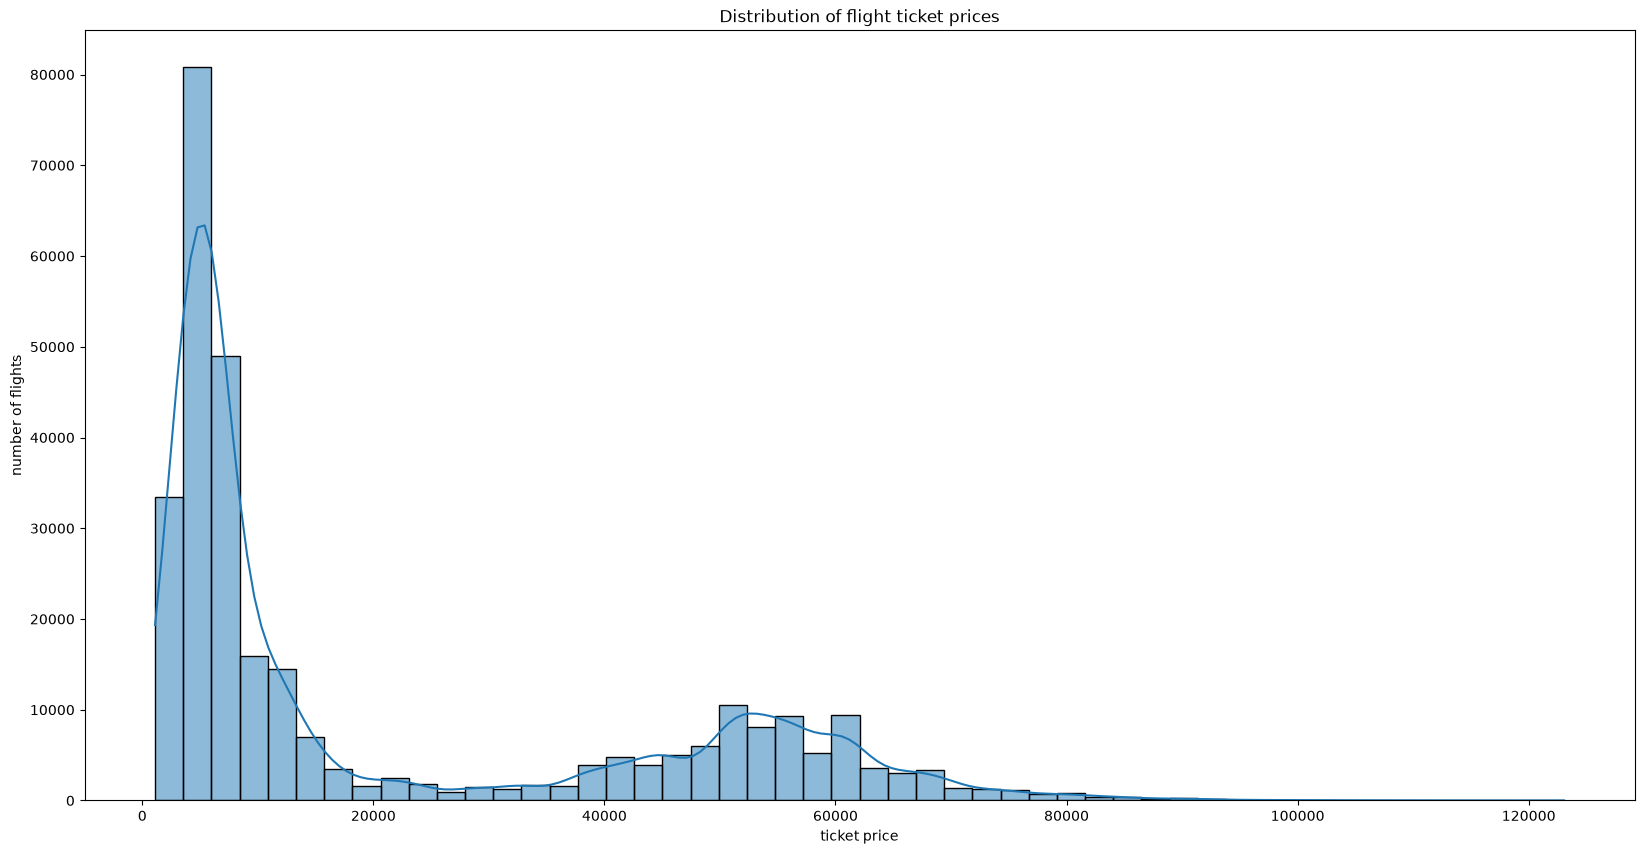

In [14]:
plt.figure(figsize=(20,10))

sns.histplot(df['price'],bins=50,kde=True) #bins divides the entire price range into 50 groups, kde is the smooth curve

plt.title('Distribution of flight ticket prices')
plt.xlabel('ticket price')
plt.ylabel('number of flights')

plt.show()

#this shows the how ticket price is distributed

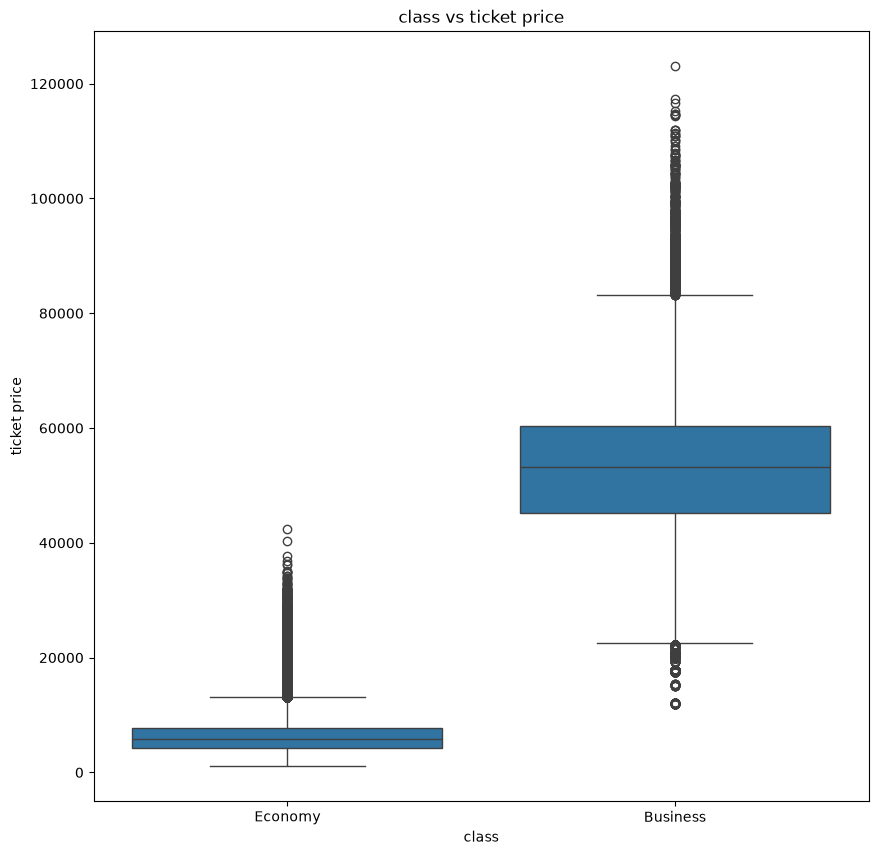

In [15]:
plt.figure(figsize=(10,10))

sns.boxplot(x='class',y='price',data=df)#helps compare the price range and median of each class

plt.title('class vs ticket price')
plt.xlabel('class')
plt.ylabel('ticket price')

plt.show()

#this graph compares ticket prices between different classes

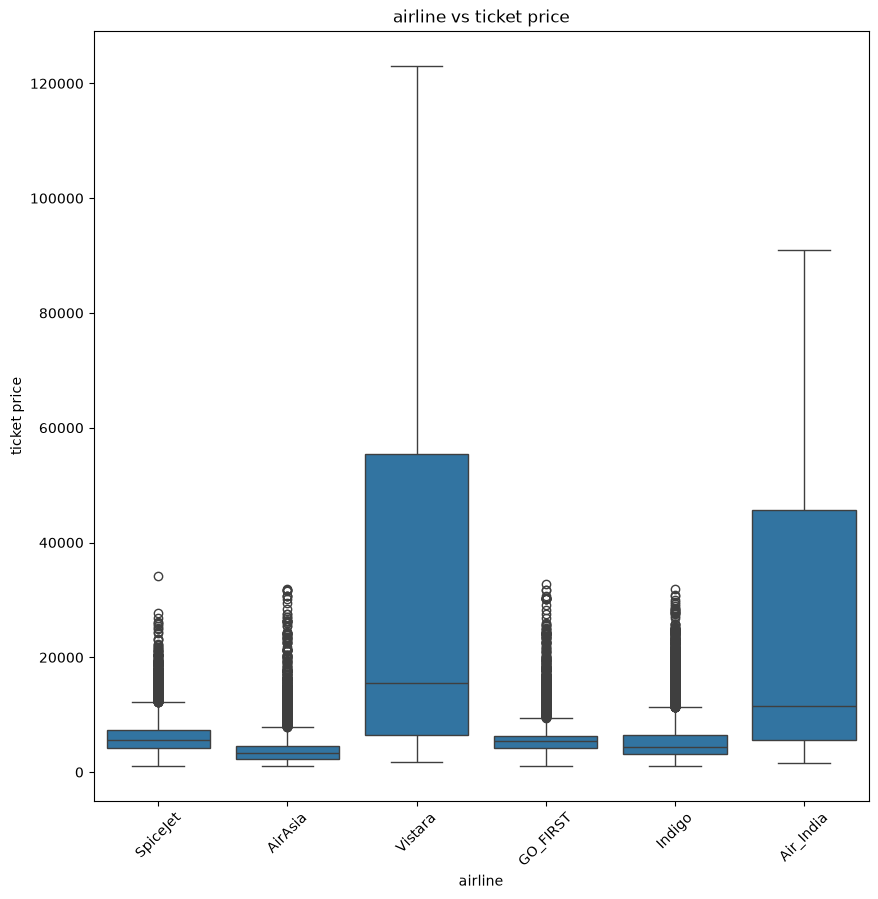

In [16]:
plt.figure(figsize=(10,10))

sns.boxplot(x='airline',y='price',data=df)

plt.title('airline vs ticket price')
plt.xlabel('airline')
plt.ylabel('ticket price')
plt.xticks(rotation=45) #used to make the name rotate for better reading

plt.show()

#this graph compares ticket prices between different airlines

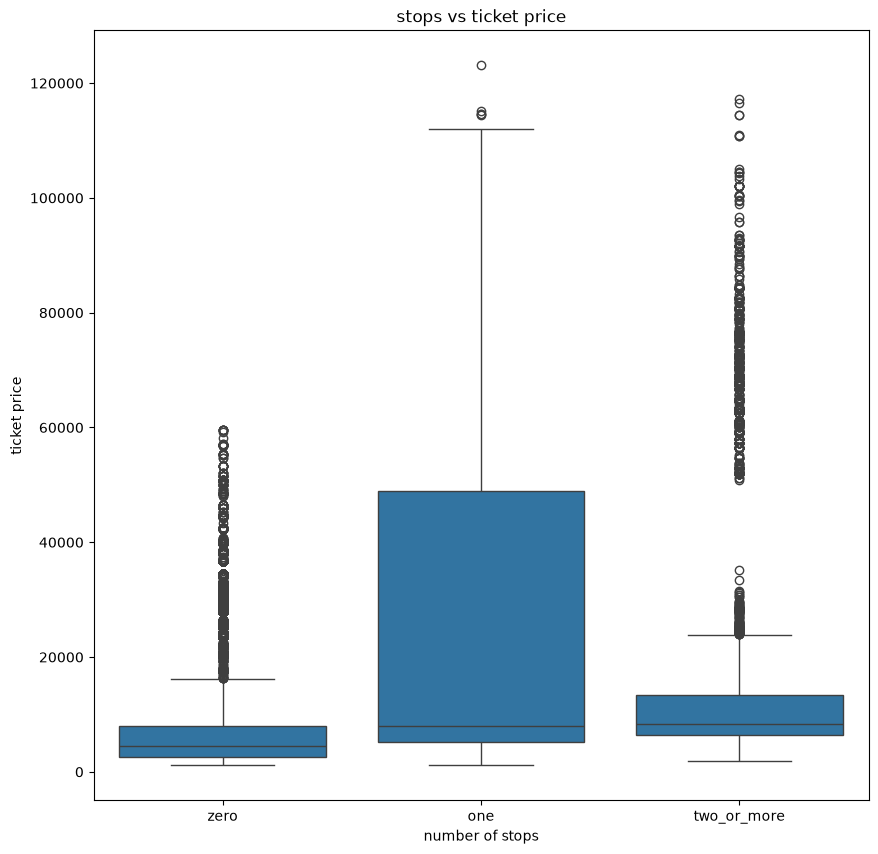

In [17]:
plt.figure(figsize=(10,10))

sns.boxplot(x='stops',y='price',data=df)

plt.title('stops vs ticket price')
plt.xlabel('number of stops')
plt.ylabel('ticket price')

plt.show()

#this graph shows the how stops affect the ticket price

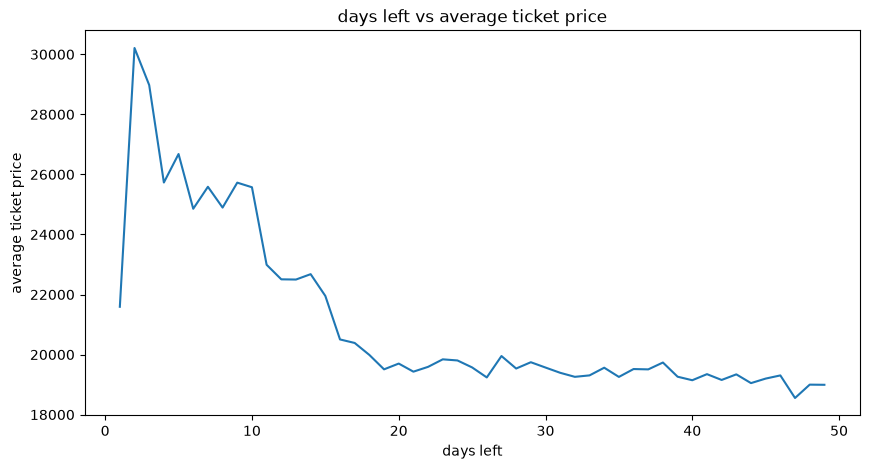

In [18]:
plt.figure(figsize=(10,5))

sns.lineplot(data=df,x='days_left',y='price',estimator='mean',errorbar=None)
#estimator='mean' to take average value
#errorbar=None removes the error bars from the graph

plt.title('days left vs average ticket price')
plt.xlabel('days left')
plt.ylabel('average ticket price')

plt.show()

#this graph shows how average ticket prices vary as the departure date approaches

### Feature preprocessing

Before building the model, we need to separate the input features and the target variable. The input features contain the flight details that help predict the ticket price, while the target variable contains the actual ticket prices we want to predict.

In [19]:
x=df.drop(['price','flight'],axis=1) #removing flight to reduce the noise
y=df['price']

In [20]:
x.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1


In [21]:
y.head()

0    5953
1    5953
2    5956
3    5955
4    5955
Name: price, dtype: int64

In [22]:
print(x.shape)
print(y.shape)

(300153, 9)
(300153,)


### splitting the dataset

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [25]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(240122, 9)
(60031, 9)
(240122,)
(60031,)


### categorical encoding

we convert categorical values into numerical representations so that the Machine Learning model can process them during training.

In [26]:
#one-hot encoding (covert categorical to 0 and 1 coumns)
x_train=pd.get_dummies(x_train,dtype=int)
x_test=pd.get_dummies(x_test,dtype=int)

x_test=x_test.reindex(columns=x_train.columns,fill_value=0)#make sure both training and testing data have the same columns

In [27]:
x_train.head()

,duration,days_left,airline_AirAsia,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,source_city_Bangalore,source_city_Chennai,...,arrival_time_Morning,arrival_time_Night,destination_city_Bangalore,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai,class_Business,class_Economy
148417,19.42,6,0,1,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,1
36879,7.00,13,0,0,0,1,0,0,0,0,...,0,1,0,1,0,0,0,0,0,1
274531,21.17,44,0,1,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
166397,10.25,11,0,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,1
272722,26.50,5,0,0,0,0,0,1,0,0,...,0,1,0,1,0,0,0,0,1,0


In [28]:
x_test.head()

,duration,days_left,airline_AirAsia,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,source_city_Bangalore,source_city_Chennai,...,arrival_time_Morning,arrival_time_Night,destination_city_Bangalore,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai,class_Business,class_Economy
27131,19.75,40,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
266857,9.83,42,0,0,0,0,0,1,0,0,...,0,1,0,0,0,0,0,1,1,0
141228,10.50,41,0,0,0,0,0,1,0,0,...,0,1,1,0,0,0,0,0,0,1
288329,14.50,14,0,0,0,0,0,1,0,1,...,1,0,0,0,1,0,0,0,1,0
97334,8.25,20,0,1,0,0,0,0,1,0,...,0,1,0,0,0,0,0,1,0,1


In [29]:
print(x_train.shape)
print(x_test.shape)

(240122, 37)
(60031, 37)


### model creation and training

we create a Random Forest Regression model and train it using our training dataset.

In [30]:
from sklearn.ensemble import RandomForestRegressor

In [31]:
rf_model=RandomForestRegressor(
    n_estimators=100, #no.of tress
    random_state=42
)

In [32]:
rf_model.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

### model predicition

In [33]:
y_pred=rf_model.predict(x_test)

#predict the ticket prices using the trained model

In [34]:
comparison=pd.DataFrame({
    'actual price':y_test,
    'predicted price':y_pred
})

comparison.head(10)

,actual price,predicted price
27131,7366,7368.04
266857,64831,71325.21
141228,6195,6195.00
288329,60160,60558.60
97334,6578,6344.21
135931,4555,6863.12
290630,23838,23838.00
141944,3860,3902.60
244517,32230,41365.91
215903,76841,65788.22


### model evaluation

In [35]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [36]:
mae=mean_absolute_error(y_test,y_pred) #average prediction mistake
mse=mean_squared_error(y_test,y_pred) #calculates the average of squared prediction errors
rmse=np.sqrt(mse) #calculates the square root of mse to get the error in the original price unit
r2=r2_score(y_test,y_pred) #measures how much variation in ticket prices is explained by the model

In [37]:
print('mean absolute error:',mae)
print('mean squared error:',mse)
print('root mean squared error:',rmse)
print('r2 score:',r2)

mean absolute error: 1077.3536478291771
mean squared error: 7765586.526245531
root mean squared error: 2786.680198057454
r2 score: 0.9849352986040014


In [38]:
rf_train_score=rf_model.score(x_train,y_train)
rf_test_score=rf_model.score(x_test,y_test)

print('training r2 score:',rf_train_score)
print('testing r2 score:',rf_test_score)

#testingg accurcy of both traing and testing

training r2 score: 0.9975282635517124
testing r2 score: 0.9849352986040014


### actual vs predicted visualization

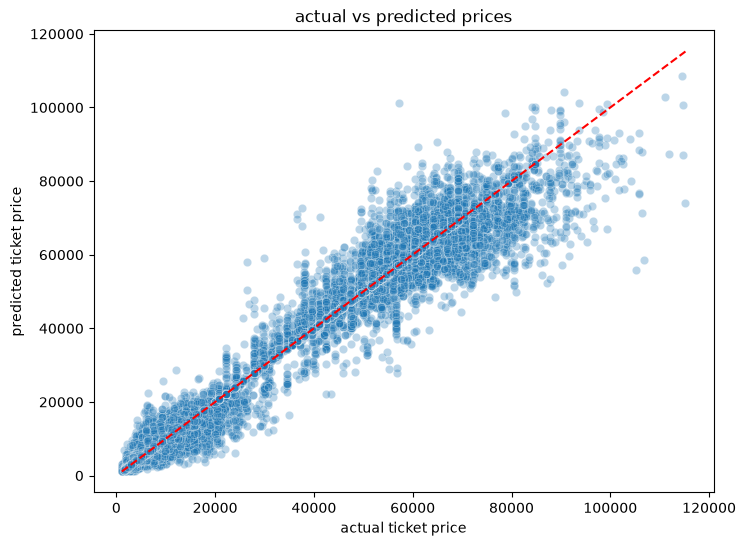

In [39]:
plt.figure(figsize=(8,6))

sns.scatterplot(x=y_test,y=y_pred,alpha=0.3)
#each dot represents an actual and predicted ticket price

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)
#the red line represents perfect predictions

plt.title('actual vs predicted prices')
plt.xlabel('actual ticket price')
plt.ylabel('predicted ticket price')

plt.show()

#this graph compares actual ticket prices with predicted prices

### conclusion

In this project, we developed a flight fare prediction model using Random Forest Regression. We started by understanding and cleaning the dataset, followed by exploratory data analysis to identify patterns and relationships between flight details and ticket prices.

We then performed data preprocessing, converted categorical values into numerical representations using One-Hot Encoding, and divided the dataset into training and testing sets. After training the Random Forest model, we evaluated its performance using different regression metrics.

The model achieved an R² score of **98.49%** on the testing data, with a Mean Absolute Error (MAE) of approximately **₹1,077** and a Root Mean Squared Error (RMSE) of approximately **₹2,787**.

These results indicate that the model performed well on the test dataset and was able to learn the relationship between flight details and ticket prices.

Overall, this project helped us understand the complete Machine Learning workflow, from data preparation and visualization to model training, prediction and evaluation.

## STREAMLIT (LOCAL DELOYMENT)

In [40]:
import joblib

joblib.dump({
    'model':rf_model,
    'columns':x_train.columns.tolist()
}, 'flight_fare_model.pkl')

['flight_fare_model.pkl']